# 15 New-plant market value: why the required rate rises with program size

**Purpose.** The required credit rate of a large SMR program rises after 2038, while the rate of a
small program falls (main-text Fig. 4a). This notebook shows the mechanism behind that split: *value
deflation*. A large fleet of new SMR capacity lowers the electricity price in the region that sets the
rate, so each later cohort of plants earns less, and the credit must cover a larger share of the cost.
The notebook reads the model's own report of what each year's new plants earn, compares that value
across the six target trajectories and five cost samples, separates the fleet's own price effect from
the price decline that the grid shows without any SMR program, and draws Supplementary Fig. 26. Its
export `m10fb` is the source of Supplementary Table 17.

**Inputs.**
- ReEDS output extracts `results/extracts/{smr100,ratedesign,itcfb}/{cap,gen_ann,reqt_price,revenue,valnew}.parquet`
  (notebook 05_extract_reeds_outputs): the 18 `smr100_*_{p05,p50,p95}` runs, the 12
  `smr100_*_{p25,p75}` anchors of the rate-design batch and the no-mandate reference run `fbR_none`.
- `results/exports/11/w01_required_rate_perworld.csv` (notebook 11_market_transfer): the region that
  sets the rate in each run and year (world = base).
- `results/exports/10/m104_requirement_fans.csv` (notebook 10_requirement_map): the median required
  rate per target trajectory and online year.
- For the side check in section 5 only: `results/extracts/{smr100,ratedesign}/cost_cap.parquet`.

**Outputs** (internal names kept).
- `results/exports/15/m10f_new_plant_value.csv`: one row per target trajectory × cost sample × solve year.
- `results/exports/15/m10fb_value_change_2038_2050.csv`: one row per target trajectory × cost sample
  (source of Supplementary Table 17).
- `results/exports/15/m10fc_price_depression_by_fleet.csv`: the fleet's price effect binned by program size.
- `results/figures/si/SF26_new_plant_value.png` (Supplementary Fig. 26).

**Paper items.** Supplementary Fig. 26, Supplementary Table 17.

**Runtime.** About 15 s on this machine (4 threads).

In [1]:
import sys
from pathlib import Path
_p = Path.cwd().resolve()
while not (_p / "nlpaper").is_dir():           # find z-ethan/ from wherever the kernel starts
    _p = _p.parent
sys.path.insert(0, str(_p))
import nlpaper
from nlpaper import paths, plotstyle as ps, h5io
nlpaper.setup(threads=4)

nlpaper setup: python 3.12.3 | numpy 1.26.4 | pandas 2.2.2 | matplotlib 3.8.4 | threads 4
determinism: seeds are explicit numpy Generators in each cell; results do not depend on PYTHONHASHSEED.


{'python': '3.12.3',
 'numpy': '1.26.4',
 'pandas': '2.2.2',
 'threads': 4,
 'threadpoolctl': True,
 'env_set': {'OMP_NUM_THREADS': '4',
  'MKL_NUM_THREADS': '4',
  'OPENBLAS_NUM_THREADS': '4',
  'NUMEXPR_NUM_THREADS': '4',
  'NUMBA_NUM_THREADS': '4'},
 'matplotlib': '3.8.4',
 'seed_note': None}

## 1. The runs and the dollar basis

**The runs.** A *target trajectory* (`schedule` in the code) is a national path of mandated SMR
capacity from one published source (EIA AEO High, ATB Moderate, IAEA High, McKinsey, COP28, 2025 EO).
A *cost sample* is one joint Monte Carlo draw of the nuclear cost inputs; the P5, P25, P50, P75 and
P95 samples sit at those percentiles of the 10,000-sample cost distribution. The 30 runs read here
(six trajectories × five samples) are the base-market anchor runs of the requirement map (notebook 10).
Every one carries the injected cost sample, no endogenous learning and no nuclear investment credit.
The P5, P50 and P95 runs come from the SMR-program batch (`smr100`); the P25 and P75 runs come from the
rate-design batch (`ratedesign`). The *no-mandate reference run* (`fbR_none`, credit-feedback batch)
solves the same grid with no SMR mandate; it shows how prices move when no SMR program exists.

**Dollars.** ReEDS reports money in 2004 dollars. The exports convert to 2024 dollars at
to2025(2004) / to2025(2024), from the model's own deflator table, and record `dollar_year = 2024` in
every row. The figure displays 2025 dollars at `ps.to2025(2024)`.

The cell below loads the five extract keys for the 31 runs and reads the two upstream exports.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

EXP = paths.exports("15")
D0424 = ps.to2025(2004) / ps.to2025(2024)      # 2004 $ -> 2024 $
TECH = "nuclear-smr"
FIX_R = "TX_HOU"                               # the fixed comparison region (section 3)
PCTS = ["p05", "p25", "p50", "p75", "p95"]
REF_CASE = "fbR_none"                          # no-mandate reference run (itcfb batch)
KEYS = ["cap", "gen_ann", "reqt_price", "revenue", "valnew"]


def batch_of(pct):
    return "smr100" if pct in ("p05", "p50", "p95") else "ratedesign"


def run_label(ab, pct):
    # the archive file stem of the run, as the source export recorded it
    return (f"test1_smr100_{ab}_{pct}" if batch_of(pct) == "smr100"
            else f"rate_design_smr100_{ab}_{pct}")


X = {b: {k: h5io.load(b, k) for k in KEYS} for b in ("smr100", "ratedesign", "itcfb")}
w01 = pd.read_csv(paths.require(paths.exports("11") / "w01_required_rate_perworld.csv",
                                "notebook 11_market_transfer"))
w01 = w01[w01.world == "base"].set_index(["case", "t"])
m104 = pd.read_csv(paths.require(paths.exports("10") / "m104_requirement_fans.csv",
                                 "notebook 10_requirement_map"))
print(f"D0424 = {D0424:.4f} (2004 $ -> 2024 $); to2025(2024) = {ps.to2025(2024):.4f}")

D0424 = 1.6590 (2004 $ -> 2024 $); to2025(2024) = 1.0260


## 2. What the model reports for each run and year

For each run the cell below builds five series, all restricted to solve years from 2031 (the first
year SMR capacity can come online).

- **New-plant value** (`valnew`). ReEDS writes this report after each solve (report.gms, `valnew`). It
  is the market value that the year's *new* SMR capacity earns in that year: energy value (`val_load`),
  reserve-margin capacity value (`val_resmarg`) and clean-energy-standard value (`val_rps`), each at
  the model's own shadow prices. The notebook sums the three over regions and divides by the new MW.
  The value is *annual* (one year, not the plant's life), *ex post* (at the solved prices) and *gross
  of O&M* (operating and maintenance cost is not subtracted). It is therefore not the capitalized,
  net-of-O&M market value that enters the required rate; the notebook uses it for its changes over
  time, not for its level.
- **Fleet revenue** (`revenue`): the revenue of the whole SMR fleet (load, reserve margin, clean-energy
  standard and storage charge categories), divided by the fleet MW.
- **Load price** (`reqt_price`, load component): the shadow price of the load-balance constraint per
  region, $/MWh. Notebook 05 stores the simple mean over the model's representative timeslices (not
  load-weighted), which is exactly what the source export computed; the national price is the simple
  mean over regions.
- **Fleet capacity** (`cap`) and **fleet generation** (`gen_ann`) give the program size and the fleet
  capacity factor.

In [3]:
def run_tables(batch, case):
    x = {k: v[v.case == case] for k, v in X[batch].items()}
    rp = x["reqt_price"]
    rp = rp[(rp["*"] == "load") & (rp.t >= 2031)]
    reg_p = rp.groupby(["r", "t"]).Value.mean() * D0424      # timeslice mean (from 05), 2024 $/MWh
    nat_p = reg_p.groupby("t").mean()                         # simple mean over regions
    vn = x["valnew"]
    vn = vn[(vn["*.1"] == TECH) & (vn.t >= 2031)]
    vn_r = vn.pivot_table(index=["*.2", "t"], columns="*", values="Value", aggfunc="sum").fillna(0.0)
    vn_r.index.names = ["r", "t"]
    for c in ("MW", "MWh", "val_load", "val_resmarg", "val_rps"):
        if c not in vn_r:
            vn_r[c] = 0.0
    vn_t = vn_r.groupby("t")[["MW", "MWh", "val_load", "val_resmarg", "val_rps"]].sum()
    rev = x["revenue"]
    rev_t = rev[(rev.i == TECH) & (rev.t >= 2031)].groupby("t").Value.sum()
    cap = x["cap"]
    cap_t = cap[(cap.i == TECH) & (cap.t >= 2031)].groupby("t").Value.sum()
    gen = x["gen_ann"]
    gen_t = gen[(gen.i == TECH) & (gen.t >= 2031)].groupby("t").Value.sum()
    return dict(vn_r=vn_r, vn_t=vn_t, rev_t=rev_t, cap_t=cap_t, gen_t=gen_t, reg_p=reg_p, nat_p=nat_p)


ref = run_tables("itcfb", REF_CASE)
assert len(ref["reg_p"]) > 0, "the no-mandate reference run fbR_none must be in the itcfb extract"

## 3. `m10f`: one row per target trajectory, cost sample and solve year

The cell below writes one row for each solve year in which the run holds SMR capacity. Beside the
new-plant value and the fleet revenue it records three load prices, each against the same price in the
no-mandate reference run:

- **Headline region.** The *headline region* is the building region with the lowest financed
  multiplier (`cost_cap_fin_mult_noITC`); it sets the uniform credit rate. Notebook 11 records it per
  run and year (`w01`, `fm_min_region`). The headline region changes between years and trajectories, so
  its price does not compare trajectories in one place.
- **TX_HOU.** One fixed region (Houston, Texas). TX_HOU is the headline region of COP28 and 2025 EO in
  every year from 2033, and of all six trajectories in 2038 in the P50 sample. It therefore compares the
  trajectories like for like. The reference-run TX_HOU price is the *reference-grid price control*: it
  shows the price decline that happens with no SMR program at all.
- **National mean.** The simple mean over all regions.

A *price ratio* divides a run's price by the reference run's price in the same region and year. A ratio
below 1 is the fleet's own price effect.

In [4]:
rows, found = [], []
for ab in ps.SCHED_ORDER:
    for pct in PCTS:
        case = f"smr100_{ab}_{pct}"
        R = run_tables(batch_of(pct), case)
        assert len(R["cap_t"]), f"{case} missing from the {batch_of(pct)} extract"
        found.append(case)
        for t in sorted(R["cap_t"].index):
            t = int(t)
            if R["cap_t"].get(t, 0.0) <= 0:
                continue
            v = R["vn_t"].loc[t] if t in R["vn_t"].index else None
            new_mw = float(v["MW"]) if v is not None else 0.0
            val = float(v[["val_load", "val_resmarg", "val_rps"]].sum()) if v is not None else np.nan
            per_kw = (lambda x: x / new_mw / 1000 * D0424) if new_mw > 0 else (lambda x: np.nan)
            wr = w01.loc[(case, t)] if (case, t) in w01.index else None
            hr = wr["fm_min_region"] if wr is not None and isinstance(wr["fm_min_region"], str) else None
            hv = R["vn_r"].loc[(hr, t)] if hr is not None and (hr, t) in R["vn_r"].index else None
            fleet_mw = float(R["cap_t"][t])

            def price(P, r):
                return float(P.get((r, t), np.nan)) if r is not None else np.nan

            rows.append(dict(
                schedule=ab, schedule_name=ps.SCHED_SHORT[ab], percentile=pct, run=run_label(ab, pct), year=t,
                status=(wr["status"] if wr is not None else "not in w01"),
                new_capacity_GW=new_mw / 1000,
                cumulative_program_GW=fleet_mw / 1000,
                valnew_per_kW_yr=per_kw(val),
                valnew_energy_per_kW_yr=per_kw(float(v["val_load"])) if v is not None else np.nan,
                valnew_capacity_per_kW_yr=per_kw(float(v["val_resmarg"])) if v is not None else np.nan,
                valnew_rps_per_kW_yr=per_kw(float(v["val_rps"])) if v is not None else np.nan,
                valnew_per_MWh=(val / float(v["MWh"]) * D0424) if v is not None and v["MWh"] > 0 else np.nan,
                valnew_headline_region_per_kW_yr=(
                    float(hv[["val_load", "val_resmarg", "val_rps"]].sum()) / float(hv["MW"]) / 1000 * D0424
                    if hv is not None and hv["MW"] > 0 else np.nan),
                fleet_revenue_per_kW_yr=float(R["rev_t"].get(t, np.nan)) / fleet_mw / 1000 * D0424,
                fleet_capacity_factor=float(R["gen_t"].get(t, np.nan)) / (fleet_mw * 8760),
                headline_region=hr,
                headline_fin_mult_noITC=(float(wr["fm_min"]) if wr is not None else np.nan),
                headline_region_load_price=price(R["reg_p"], hr),
                reference_load_price_same_region=price(ref["reg_p"], hr),
                txhou_load_price=price(R["reg_p"], FIX_R),
                reference_txhou_load_price=price(ref["reg_p"], FIX_R),
                national_mean_load_price=float(R["nat_p"].get(t, np.nan)),
                reference_national_mean_load_price=float(ref["nat_p"].get(t, np.nan)),
                dollar_year=2024,
            ))
df = pd.DataFrame(rows)
df["headline_price_ratio"] = df.headline_region_load_price / df.reference_load_price_same_region
df["txhou_price_ratio"] = df.txhou_load_price / df.reference_txhou_load_price
df["national_price_ratio"] = df.national_mean_load_price / df.reference_national_mean_load_price
assert len(found) == 30, "30 base-market anchor runs: six trajectories x five cost samples"
assert len(df) == 275, "275 solved sample-years with SMR capacity (the SI's count)"
df.to_csv(EXP / "m10f_new_plant_value.csv", index=False)
print(f"runs {len(found)}; rows {len(df)}")
print(df.groupby("status").size().to_string())

runs 30; rows 275
status
rate                           274
slack: required ITC is zero      1


## 4. `m10fb` and `m10fc`: the 2038→2050 change and the price effect by program size

**`m10fb`** gives one row per trajectory and cost sample: the new-plant value, the fleet revenue and the
TX_HOU price in 2038, 2041 and 2050, their percent changes, the 2050 price ratios, and the median
required rate of notebook 10 (`m104`, the band-centre median of the 10,000 cost samples, quantity
`rate`) in 2038, 2041 and 2050. 2038 is the paper's common window; 2041 is the first year after the
early build-out. Supplementary Table 17 prints its P50 rows (sub-table a) and the 2038→2050 value
change of all five samples (sub-table b).

**`m10fc`** bins all 275 sample-years by program size (cumulative SMR GW) and reports the TX_HOU price
ratio per bin: its range and median and the share of sample-years more than 5% below the reference.
The per-solve build increment rises with fleet size, so the bins describe "the fleet and the pace of
additions" together, not the fleet alone.

In [5]:
m104r = m104[(m104.quantity == "rate") & (m104.band == "base")].set_index(["schedule", "year"]).p50
ch = []
for (ab, pct), g in df.groupby(["schedule", "percentile"], sort=False):
    g = g.set_index("year")

    def get(col, t):
        return float(g[col].get(t, np.nan))

    def pc(col, a, b=2050):
        return 100 * (get(col, b) / get(col, a) - 1)

    rec = dict(schedule=ab, schedule_name=ps.SCHED_SHORT[ab], percentile=pct,
               program_GW_2038=get("cumulative_program_GW", 2038),
               program_GW_2050=get("cumulative_program_GW", 2050),
               valnew_2038=get("valnew_per_kW_yr", 2038), valnew_2041=get("valnew_per_kW_yr", 2041),
               valnew_2050=get("valnew_per_kW_yr", 2050),
               valnew_change_2038_2050_pct=pc("valnew_per_kW_yr", 2038),
               valnew_change_2041_2050_pct=pc("valnew_per_kW_yr", 2041),
               fleet_revenue_2038=get("fleet_revenue_per_kW_yr", 2038),
               fleet_revenue_2041=get("fleet_revenue_per_kW_yr", 2041),
               fleet_revenue_2050=get("fleet_revenue_per_kW_yr", 2050),
               fleet_revenue_change_2038_2050_pct=pc("fleet_revenue_per_kW_yr", 2038),
               fleet_revenue_change_2041_2050_pct=pc("fleet_revenue_per_kW_yr", 2041),
               txhou_price_2038=get("txhou_load_price", 2038), txhou_price_2050=get("txhou_load_price", 2050),
               txhou_price_change_2038_2050_pct=pc("txhou_load_price", 2038),
               txhou_price_change_2041_2050_pct=pc("txhou_load_price", 2041),
               reference_txhou_price_2038=get("reference_txhou_load_price", 2038),
               reference_txhou_price_2050=get("reference_txhou_load_price", 2050),
               reference_txhou_price_change_2038_2050_pct=pc("reference_txhou_load_price", 2038),
               reference_txhou_price_change_2041_2050_pct=pc("reference_txhou_load_price", 2041),
               reference_national_price_change_2038_2050_pct=pc("reference_national_mean_load_price", 2038),
               txhou_price_ratio_2050=get("txhou_price_ratio", 2050),
               headline_region_2050=g["headline_region"].get(2050),
               headline_price_ratio_2050=get("headline_price_ratio", 2050),
               national_price_ratio_2050=get("national_price_ratio", 2050),
               median_rate_2038=float(m104r.get((ab, 2038), np.nan)),
               median_rate_2041=float(m104r.get((ab, 2041), np.nan)),
               median_rate_2050=float(m104r.get((ab, 2050), np.nan)),
               dollar_year=2024)
    rec["schedule_order"] = ps.SCHED_ORDER.index(ab)
    rec["median_rate_2038_pct"] = 100 * rec["median_rate_2038"]
    rec["median_rate_2050_pct"] = 100 * rec["median_rate_2050"]
    rec["median_rate_change_2038_2050_pts"] = 100 * (rec["median_rate_2050"] - rec["median_rate_2038"])
    rec["median_rate_change_2041_2050_pts"] = 100 * (rec["median_rate_2050"] - rec["median_rate_2041"])
    ch.append(rec)
CH = pd.DataFrame(ch)
assert len(CH) == 30, "one row per target trajectory x cost sample"
CH.to_csv(EXP / "m10fb_value_change_2038_2050.csv", index=False)

p50 = CH[CH.percentile == "p50"].set_index("schedule_name")
F25 = ps.to2025(2024)
show = p50[["program_GW_2050", "valnew_2038", "valnew_2050", "valnew_change_2038_2050_pct",
            "fleet_revenue_change_2041_2050_pct", "txhou_price_ratio_2050",
            "median_rate_change_2038_2050_pts"]].copy()
show[["valnew_2038", "valnew_2050"]] *= F25                   # display in 2025 $/kW-yr
print("P50 sample of each trajectory (value in 2025 $/kW-yr):")
print(show.round(2).to_string())
print(f"reference-grid TX_HOU price change 2038->2050: "
      f"{CH.reference_txhou_price_change_2038_2050_pct.iloc[0]:+.1f}% "
      f"({CH.reference_txhou_price_2038.iloc[0]*F25:.1f} -> {CH.reference_txhou_price_2050.iloc[0]*F25:.1f} 2025 $/MWh)")

P50 sample of each trajectory (value in 2025 $/kW-yr):
               program_GW_2050  valnew_2038  valnew_2050  valnew_change_2038_2050_pct  fleet_revenue_change_2041_2050_pct  txhou_price_ratio_2050  median_rate_change_2038_2050_pts
schedule_name                                                                                                                                                                      
EIA AEO High              20.7       466.90       528.90                        13.28                               -1.23                    0.99                            -16.25
ATB Moderate              36.4       477.42       461.52                        -3.33                               -8.10                    0.98                             -2.18
IAEA High                 75.7       478.44       434.71                        -9.14                               -7.61                    0.96                              0.41
McKinsey                 103.4       468.35  

In [6]:
bins = [0, 25, 50, 75, 100, 125, 150, 200, 250, 310]
b = df.dropna(subset=["txhou_price_ratio"]).copy()
b["gw_bin"] = pd.cut(b.cumulative_program_GW, bins, right=False)
fc = b.groupby("gw_bin", observed=True).agg(
    n_run_years=("txhou_price_ratio", "size"),
    ratio_min=("txhou_price_ratio", "min"), ratio_median=("txhou_price_ratio", "median"),
    ratio_max=("txhou_price_ratio", "max"),
    share_below_095=("txhou_price_ratio", lambda s: float((s < 0.95).mean())),
    national_ratio_median=("national_price_ratio", "median")).reset_index()
fc["gw_bin"] = fc.gw_bin.astype(str)
fc.to_csv(EXP / "m10fc_price_depression_by_fleet.csv", index=False)
print(fc.round(3).to_string())

       gw_bin  n_run_years  ratio_min  ratio_median  ratio_max  share_below_095  national_ratio_median
0     [0, 25)          145      0.932         0.989      1.001            0.062                  0.993
1    [25, 50)           55      0.896         0.945      0.991            0.564                  0.969
2    [50, 75)           20      0.858         0.931      0.980            0.650                  0.951
3   [75, 100)           15      0.854         0.926      0.973            0.667                  0.931
4  [100, 125)           15      0.786         0.872      0.947            1.000                  0.897
5  [150, 200)           10      0.707         0.788      0.848            1.000                  0.822
6  [200, 250)           10      0.661         0.723      0.811            1.000                  0.777
7  [250, 310)            5      0.631         0.656      0.697            1.000                  0.725


**How to read the numbers.** In the P50 sample the new-plant value changes from 2038 to 2050 by +13%
(EIA AEO High), −3% (ATB Moderate), −9% (IAEA High), −11% (McKinsey), −25% (COP28) and −25% (2025 EO).
The reference-grid TX_HOU price falls 11% over the same years, and every trajectory shares that
decline. Programs below about 100 GW therefore lose value with the reference grid or less. The COP28 and
2025 EO programs lose a quarter of their value, because their own fleet pushes the TX_HOU price 21% and
34% below the reference by 2050. Each row is one solved cost sample, not a distribution; the five
samples bracket the spread.

**Artifacts that carry no claim.** Three features of the value and rate paths are not program effects,
and the paper draws no conclusion from them:
- **The 2031 first-cohort premium.** 2031 is a low-price model year: the reference-run TX_HOU price is
  34.6 2024 $/MWh in 2031 and 40.5 in 2032. The first cohort therefore earns little, and its median
  rate sits above the later years' rates. Every mandate run shares the 2031→2032 price rise, so the low
  2031 values and the 2032 peak follow the reference grid, not the program.
- **The ATB Moderate 2032 dip.** One small cohort (0.4 GW) built in one high-value region (NY_NYC)
  raises the 2032 value of ATB Moderate and sets its rate basis, so its median rate dips to 47.7%.
- **The 2047→2050 uptick.** Some rate and value paths turn in the last solve years. 2050 is the model
  horizon, and the end of the horizon shapes the last solves, so the turn is not read as a trend.

## 5. How the value change relates to the rate change (main-text Fig. 4a)

The required rate `i` is the share of the financed capital cost `C` that a credit must cover so that the
cost of a plant falls to its market value. The shadow price `S` of the SMR mandate is the gap between
cost and value that the model reports. On the basis of Fig. 4a, `C` is the national overnight cost
(`cost_cap`) times the financed multiplier of the headline region (`cost_cap_fin_mult_noITC`, which
already holds the construction-financing and the regional factors). On that basis the rate is a fixed multiple of `S/C`:
`i = (k/0.9) · S/C ≈ 1.02 · S/C`. Here k = (1 − τ·PV_dep)/(1 − τ·PV_dep/2) ≈ 0.92 accounts for the
depreciation basis that an investment credit halves (τ is the tax rate, PV_dep the present value of
depreciation), and 0.9 is the 10% monetization haircut (the share of a credit's face value lost when it
is sold for cash). Notebook 11 computes the headline
rate in `w01` on this basis, so the cell below is a basis check, not an independent test: it rebuilds
`C` from the `cost_cap` extract and the `w01` multiplier and confirms the constant over all solved
sample-years (no export).

Hence a fall in new-plant value raises `S` at a given cost, and the rate rises with it. The rate labels
in panel (b) of the figure are the 2038→2050 changes of the median rate: −16, −2, +0, +2, +16 and
+20 points in the trajectory order above. They move in the same order as the value changes.

In [7]:
cc = pd.concat([h5io.load("smr100", "cost_cap"), h5io.load("ratedesign", "cost_cap")])
cc = cc[cc.i == TECH].set_index(["case", "t"]).Value
w = w01.reset_index()
w = w[w.case.isin(found) & (w.status == "rate")].copy()
w["C_2004_per_MW"] = [float(cc.get((c, t), np.nan)) for c, t in zip(w.case, w.t)] * w.fm_min
w["i_C_over_S"] = w.i_model_headline_raw * w.C_2004_per_MW / w.S_t_2004_per_MW
q = w.i_C_over_S.dropna()
print(f"i*C/S over {len(q)} solved sample-years: median {q.median():.4f}, "
      f"range {q.min():.4f}-{q.max():.4f}, sd {q.std():.1e}  (= k/0.9 on the headline-region financed basis)")

i*C/S over 274 solved sample-years: median 1.0215, range 1.0215-1.0215, sd 6.8e-07  (= k/0.9 on the headline-region financed basis)


## 6. Supplementary Fig. 26

- **(a)** The new-plant value of each online year in the P50 sample of each trajectory, 2025 $/kW-yr.
  The grey dashed line is the 2038 mean of the six values moved only with the reference run's TX_HOU
  load price. It is the part of the decline common to all trajectories, on the same axis and unit.
- **(b)** The 2038→2050 change in new-plant value against the 2050 program size (log scale), for all
  five cost samples (large dot: P50; small dots: P5, P25, P75, P95). The label beside each large dot is
  the 2038→2050 change in the median required rate, in rate points (main-text Fig. 4a). The dashed line
  is the reference-grid price change over the same years.

saved -> analysis\results\figures\si\SF26_new_plant_value.png


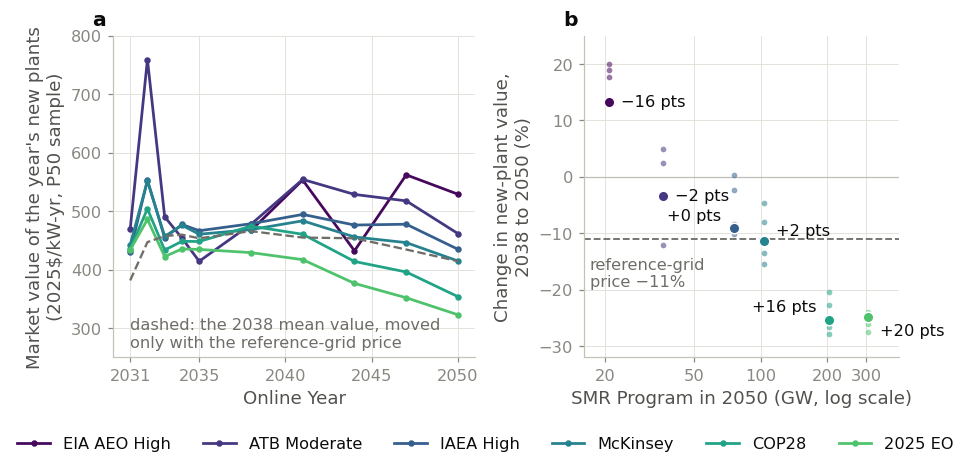

In [8]:
CW = 8.62
PF = ps.fonts(CW)
GREY = "#6f6d68"
MINUS = "\u2212"
ps.apply()
d, c = df, CH
p50s = d[d.percentile == "p50"]

fig, (ax, bx) = plt.subplots(1, 2, figsize=(CW, 3.7), gridspec_kw=dict(width_ratios=[1.15, 1]))

# (a) value by year
for ab in ps.SCHED_ORDER:
    g = p50s[p50s.schedule == ab].sort_values("year")
    ax.plot(g.year, g.valnew_per_kW_yr * F25, color=ps.SCHED_C[ab], lw=1.8,
            marker="o", ms=3.2, label=ps.SCHED_SHORT[ab])
refp = p50s[p50s.schedule == "eo"].set_index("year").reference_txhou_load_price
v38 = (p50s[p50s.year == 2038].valnew_per_kW_yr * F25).mean()
ax.plot(refp.index, v38 * refp / refp[2038], color=GREY, lw=1.5, ls="--")
ax.text(2031, 290, "dashed: the 2038 mean value, moved\nonly with the reference-grid price",
        color=GREY, fontsize=PF["annotation"], va="center", ha="left")
ax.set_xlim(2030, 2051)
ax.set_ylim(250, 800)
ax.set_xticks([2031, 2035, 2040, 2045, 2050])
ax.set_xlabel("Online Year", fontsize=PF["axis_label"])
ax.set_ylabel("Market value of the year's new plants\n(2025$/kW-yr, P50 sample)",
              fontsize=PF["axis_label"])
ax.tick_params(labelsize=PF["tick"])

# (b) change 2038 -> 2050 against 2050 program size
ref_ch = float(c.reference_txhou_price_change_2038_2050_pct.iloc[0])
bx.axhline(0, color="#bdbbb5", lw=0.8)
bx.axhline(ref_ch, color=GREY, lw=1.2, ls="--")
bx.text(17, ref_ch - 3.2, "reference-grid\nprice " + f"{ref_ch:+.0f}%".replace("-", MINUS),
        color=GREY, fontsize=PF["annotation"], ha="left", va="top")
LAB = {"iaea": ((-8, 8), "right"), "mck": ((8, 7), "left"),
       "cop28": ((-8, 9), "right"), "eo": ((8, -9), "left")}
for ab in ps.SCHED_ORDER:
    g = c[c.schedule == ab]
    o = g[g.percentile != "p50"]
    bx.scatter(o.program_GW_2050, o.valnew_change_2038_2050_pct, s=14, color=ps.SCHED_C[ab],
               alpha=0.55, lw=0, zorder=3)
    m = g[g.percentile == "p50"].iloc[0]
    bx.scatter(m.program_GW_2050, m.valnew_change_2038_2050_pct, s=48, color=ps.SCHED_C[ab],
               edgecolor="white", lw=1.0, zorder=4)
    off, ha = LAB.get(ab, ((8, 0), "left"))
    bx.annotate(f"{m.median_rate_change_2038_2050_pts:+.0f} pts".replace("-", MINUS),
                (m.program_GW_2050, m.valnew_change_2038_2050_pct), xytext=off, ha=ha,
                textcoords="offset points", fontsize=PF["annotation"], color=ps.INK, va="center")
bx.set_xscale("log")
bx.set_xticks([20, 50, 100, 200, 300])
bx.set_xticklabels(["20", "50", "100", "200", "300"])
bx.minorticks_off()
bx.set_xlim(16, 420)
bx.set_ylim(-32, 25)
bx.set_xlabel("SMR Program in 2050 (GW, log scale)", fontsize=PF["axis_label"])
bx.set_ylabel("Change in new-plant value,\n2038 to 2050 (%)", fontsize=PF["axis_label"])
bx.tick_params(labelsize=PF["tick"])
# The key to panel b (label = change in the median Equivalent ITC, 2038 to 2050; large dot = P50
# sample, small dots = P5, P25, P75, P95) is stated in the caption, not drawn.

handles = [Line2D([], [], color=ps.SCHED_C[ab], lw=1.8, marker="o", ms=3.2,
                  label=ps.SCHED_SHORT[ab]) for ab in ps.SCHED_ORDER]
fig.legend(handles=handles, ncol=6, fontsize=PF["legend"], frameon=False, loc="upper center",
           bbox_to_anchor=(0.5, 0.0))
fig.tight_layout()
ps.letter_panels([ax, bx], size=PF["panel_letter"])
ps.savefig(fig, paths.FIGS_SI / "SF26_new_plant_value.png")
plt.show()